In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit

In [8]:
data = sm.datasets.sunspots.load_pandas().data

X = np.arange(len(data)).reshape(-1, 1)
y = data['SUNACTIVITY'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


In [9]:
# Create and train the ARIMA model
arima_model = ARIMA(y_train, order=(5, 1, 5))
arima_model_fit = arima_model.fit()

# Predict and evaluate ARIMA
y_pred_arima = arima_model_fit.forecast(steps=len(y_test))
print("ARIMA MSE:", mean_squared_error(y_test, y_pred_arima))

ARIMA MSE: 1548.0222278403085


c:\Users\HansP\Documents\Artificial-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [10]:
# Create and train the MLP
mlp = MLPRegressor(hidden_layer_sizes=(10,), activation='relu', solver='adam',
max_iter=2500)
mlp.fit(X_train, y_train)

# Predict and evaluate MLP
y_pred_mlp = mlp.predict(X_test)
print("MLP MSE:", mean_squared_error(y_test, y_pred_mlp))

MLP MSE: 2949.3343067510364


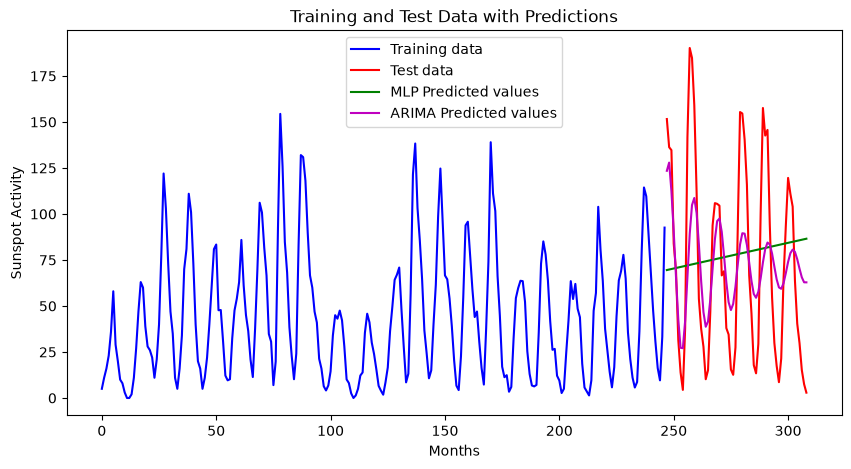

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(X_train[:, -1], y_train, 'b-', label='Training data')
plt.plot(X_test, y_test, 'r-', label='Test data')
plt.plot(X_test, y_pred_mlp, 'g-', label='MLP Predicted values')
plt.plot(X_test, y_pred_arima, 'm-', label='ARIMA Predicted values')
plt.legend()
plt.title('Training and Test Data with Predictions')
plt.xlabel('Months')
plt.ylabel('Sunspot Activity')
plt.show()

In [12]:
# Normalize the data
scaler = StandardScaler()
y_scaled = scaler.fit_transform(y.reshape(-1, 1)).ravel()

In [17]:
def create_lagged_features(y, lag=5):
    X, y_lagged = [], []
    for i in range(lag, len(y)):
        X.append(y[i-lag:i])
        y_lagged.append(y[i])
    return np.array(X), np.array(y_lagged)
X_lagged, y_lagged = create_lagged_features(y_scaled)

In [18]:
X_train_lagged, X_test_lagged, y_train_lagged, y_test_lagged = train_test_split(X_lagged,y_lagged, test_size=0.2, shuffle=False)

In [19]:
# Create and train the MLP with cross-validation
tscv = TimeSeriesSplit(n_splits=5)
mlp = MLPRegressor(hidden_layer_sizes=(50, 25), activation='relu', solver='adam',
max_iter=1000)

for train_index, test_index in tscv.split(X_train_lagged):
    X_train_cv, X_test_cv = X_train_lagged[train_index], X_train_lagged[test_index]
    y_train_cv, y_test_cv = y_train_lagged[train_index], y_train_lagged[test_index]
    mlp.fit(X_train_cv, y_train_cv)

In [20]:
y_pred_mlp = mlp.predict(X_test_lagged)
y_pred_mlp = scaler.inverse_transform(y_pred_mlp.reshape(-1, 1)).ravel()
y_test_lagged = scaler.inverse_transform(y_test_lagged.reshape(-1, 1)).ravel()
print("Improved MLP MSE:", mean_squared_error(y_test_lagged, y_pred_mlp))

Improved MLP MSE: 518.6257068991979


In [21]:
# ARIMA for standardised data
# Create and train the ARIMA model
arima_model = ARIMA(y_train, order=(5, 1, 5))
arima_model_fit = arima_model.fit()
# Predict and evaluate ARIMA
y_pred_arima = arima_model_fit.forecast(steps=len(y_test))
print("ARIMA MSE:", mean_squared_error(y_test, y_pred_arima))      

ARIMA MSE: 1548.0222278403085


c:\Users\HansP\Documents\Artificial-Intelligence\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [22]:
# Ensure the lengths match
min_length = min(len(y_test), len(y_pred_arima), len(y_pred_mlp))
y_test = y_test[:min_length]
y_pred_arima = y_pred_arima[:min_length]
y_pred_mlp = y_pred_mlp[:min_length]
X_test = X_test[:min_length]

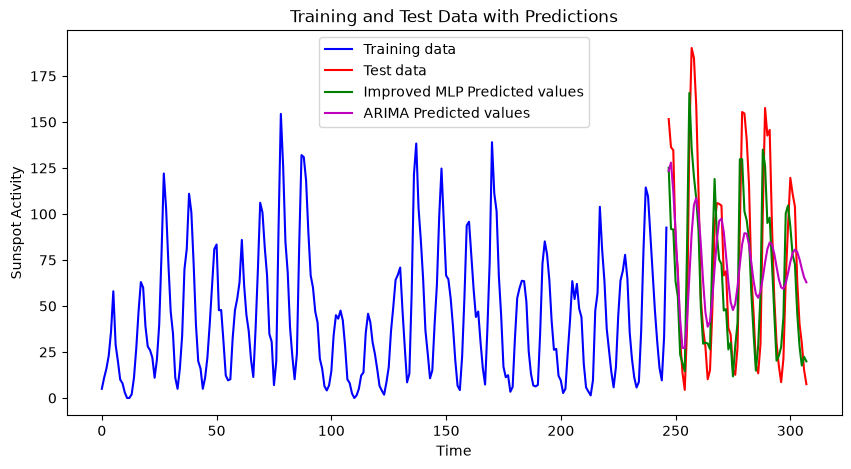

In [23]:
# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(X_train[:, -1], y_train, 'b-', label='Training data')
plt.plot(X_test, y_test, 'r-', label='Test data')
plt.plot(X_test, y_pred_mlp, 'g-', label='Improved MLP Predicted values')
plt.plot(X_test, y_pred_arima, 'm-', label='ARIMA Predicted values')
plt.legend()
plt.title('Training and Test Data with Predictions')
plt.xlabel('Time')
plt.ylabel('Sunspot Activity')
plt.show()